In [1]:
import sys, os
sys.path.append("..")

import usf

In [2]:
usf_folders = ['C:/Users/au646858/Downloads/USF_Files_dawa river/',
               #'/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/']
            ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)


data_overview, df_data = usf.sweep2dataframes(sweeps)

# df_data.loc[df_data['time']>1e-3, 'inuse_auto'] = False
# df_data = df_data.sort_values(by=['site_id','system_id', 'gate_id'])

In [3]:
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps

In [4]:
df_data['include'] = df_data['inuse_auto']

In [5]:
pivot = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values='dbdt'
)

In [6]:
# Create pivot table with multiple values
pivot_multi = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include']
)

# Flatten the multi-level column names
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
pivot_multi

,dbdt_0.0,dbdt_0.01,dbdt_0.02,dbdt_0.03,dbdt_0.04,dbdt_0.05,dbdt_1.0,dbdt_1.01,dbdt_1.02,dbdt_1.03,...,include_1.12,include_1.13,include_1.1400000000000001,include_1.15,include_1.16,include_1.17,include_1.18,include_1.19,include_1.2,include_1.21
site_id,,,,,,,,,,,,,,,,,,,,,
0,0.000008,0.000005,2.960390e-06,1.716670e-06,9.905290e-07,5.755000e-07,1.246170e-06,6.747170e-07,3.695650e-07,2.045410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,0.000005,0.000003,1.777440e-06,1.070710e-06,6.543040e-07,4.038660e-07,8.063070e-07,4.697770e-07,2.770680e-07,1.646370e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,0.000004,0.000003,1.760430e-06,1.135900e-06,7.274330e-07,4.618690e-07,8.772410e-07,5.313900e-07,3.197160e-07,1.914410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,0.000006,0.000004,2.421000e-06,1.522140e-06,9.499710e-07,5.866660e-07,1.156850e-06,6.788090e-07,3.943070e-07,2.269800e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.000004,0.000002,1.545860e-06,9.725170e-07,6.080860e-07,3.786440e-07,7.421770e-07,4.394710e-07,2.611980e-07,1.562060e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,0.000002,0.000001,9.014080e-07,5.925550e-07,3.889980e-07,2.556770e-07,4.679400e-07,2.939610e-07,1.851020e-07,1.167700e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,0.000004,0.000002,1.409740e-06,8.513620e-07,5.201450e-07,3.211830e-07,6.428770e-07,3.743210e-07,2.214700e-07,1.328950e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,0.000006,0.000004,2.039370e-06,1.177080e-06,6.872580e-07,4.058750e-07,8.644760e-07,4.780200e-07,2.697180e-07,1.551280e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,0.000004,0.000002,1.316900e-06,8.128670e-07,5.068250e-07,3.182930e-07,6.204600e-07,3.692040e-07,2.225660e-07,1.354880e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [7]:
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.forwards import Forward

import numpy as np

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, swp.tx_ramp)
        filter_chain = []

        for f_cut, order in zip(swp.low_pass[::2], swp.low_pass[1::2]):
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

In [8]:
import matplotlib.pyplot as plt
from anemone.inversion import *
from anemone.forwards import *
import torch

logForward = logify_forward(Forward)
fwrs = sweep2fwr(sweeps, fwr=logForward)

fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

dmfwr = fwrs[0]+fwrs[1]


rho = torch.tensor([20, 10, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**dmfwr(rho, thk)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.cumsum(torch.logspace(0,1.5,30), 0))
fastJac = fastjacobian(Tikhonov)

In [9]:
data_overview, df_data = usf.sweep2dataframes(sweeps)

df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
row = pivot_multi.loc[15]

dbdt_values  = row.filter(like='dbdt_').values
error_values = row.filter(like='error_').values
include_values = row.filter(like='include_').values.astype(bool)

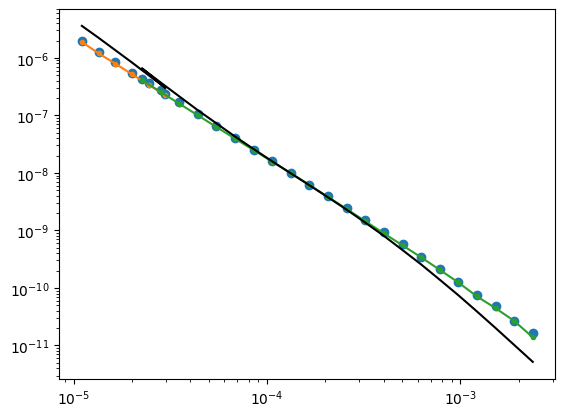

In [10]:
d_obs = torch.from_numpy(dbdt_values).abs()#.log10()

# d_true = 10**torch.concat([fwr(rho, thk) for fwr in fwrs])
# d_time = torch.concat([fwr.times for fwr in fwrs])

plt.figure()
plt.loglog(dmfwr.times, d_obs, 'o', label='Observed Data')
plt.plot(lm.time[14], lm.data[14], '.-')
plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**dmfwr(rho,thk), 'k-', label='True Model')

In [11]:
d_obs = torch.from_numpy(dbdt_values).abs().log10()
d_err = torch.from_numpy(np.log10(1. + error_values/100.))

include_mask = include_values.astype(bool)
d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

inv = fastJac(d_obs, d_err, res_start, dmfwr)
inv.data_misfit_acceptance_threshold = 1.
res_mod = inv.invert(iter_cap=10)

001	misfit:	12.74
002	misfit:	3.41
003	misfit:	1.75
004	misfit:	1.33
005	misfit:	1.12
006	misfit:	0.99
misfit is below 1.0, stopping inversion


In [12]:
d_syn = inv.forward(*res_mod.mod)

In [13]:
d_syn

tensor([ -5.7009,  -5.8922,  -6.0823,  -6.2679,  -6.4561,  -6.6430,  -6.3482,
         -6.5556,  -6.7617,  -6.9703,  -7.1759,  -7.3860,  -7.5927,  -7.8013,
         -8.0081,  -8.2130,  -8.4182,  -8.6187,  -8.8225,  -9.0226,  -9.2302,
         -9.4394,  -9.6595,  -9.8872, -10.1277, -10.3804, -10.6453, -10.9229],
       dtype=torch.float64)

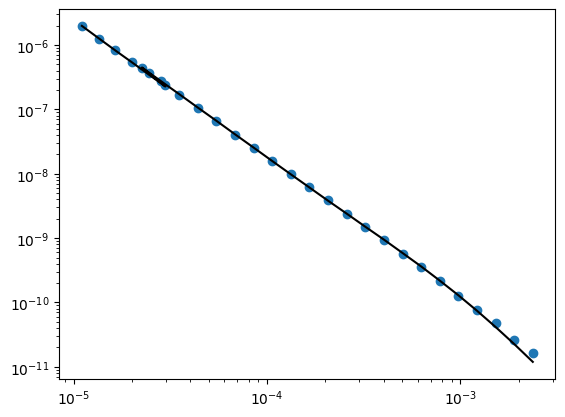

In [14]:
plt.figure()
plt.loglog(dmfwr.times, 10**d_obs, 'o', label='Observed Data')
# plt.plot(lm.time[14], lm.data[14], '.-')
# plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**d_syn, 'k-', label='True Model')

In [15]:
data_overview

,date,elevation,latitude,longitude
site_id,,,,
0,20250227.0,196.0,4.145819,42.060207
1,20250227.0,190.0,4.146311,42.060470
2,20250227.0,193.0,4.147010,42.060660
3,20250227.0,192.0,4.147274,42.060783
4,20250227.0,178.0,4.147556,42.060863
5,20250227.0,178.0,4.147841,42.060873
6,20250227.0,176.0,4.148134,42.060849
7,20250227.0,177.0,4.148484,42.060624
8,20250227.0,178.0,4.148728,42.060495


In [16]:
import pandas as pd

def silence(s):
    pass

data_overview, df_data = usf.sweep2dataframes(sweeps)
df_overview = df_res.pivot_table(
    index=['site_id'],
    values=['date', 'daytime', 'latitude', 'longitude', 'elevation'],
    aggfunc='first'
)


df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include', 'data_id'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

pivot_multi.sort_values(by='site_id', inplace=True)
df_overview.sort_values(by='site_id', inplace=True)

In [17]:
results = []
for i,(row,row_meta) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    if i==1:
        print(row)
        print(row_meta)

(1, data_id_0.0     61.0
data_id_0.01    62.0
data_id_0.02    63.0
data_id_0.03    64.0
data_id_0.04    65.0
                ... 
include_1.17     1.0
include_1.18     1.0
include_1.19     1.0
include_1.2      1.0
include_1.21     1.0
Name: 1, Length: 112, dtype: float64)
(1, date         2.025023e+07
daytime      1.218500e+01
elevation    1.900000e+02
latitude     4.146311e+00
longitude    4.206047e+01
Name: 1, dtype: float64)


In [ ]:
results = []
for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    dbdt_values  = row.filter(like='dbdt_').values
    error_values = row.filter(like='error_').values
    include_values = row.filter(like='include_').values
    data_id = row.filter(like='data_id_').values

    d_obs = torch.from_numpy(dbdt_values).abs().log10()
    d_err = torch.from_numpy(np.log10(1. + error_values/100.))
    include_mask = include_values.astype(bool)
    d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

    inv = fastJac(d_obs, d_err, res_start, dmfwr, logger=silence)
    inv.data_misfit_acceptance_threshold = 0.95
    res_mod = inv.invert(iter_cap=10)



    d_syn = 10**inv.forward(*res_mod.mod)
    df_res.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

    rho,thick = res_mod.mod
    row_meta['site_id'] = id_meta
    row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
    row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
    results.append(row_meta.to_dict())
    print(f'Inversion for data_id {i:02d} completed.')

df_resmod = pd.DataFrame(results)

Inversion for data_id 00 completed.
Inversion for data_id 01 completed.
Inversion for data_id 02 completed.
Inversion for data_id 03 completed.
Inversion for data_id 04 completed.
Inversion for data_id 05 completed.
Inversion for data_id 06 completed.
Inversion for data_id 07 completed.
Inversion for data_id 08 completed.
Inversion for data_id 09 completed.
Inversion for data_id 10 completed.
Inversion for data_id 11 completed.
Inversion for data_id 12 completed.
Inversion for data_id 13 completed.
Inversion for data_id 14 completed.
Inversion for data_id 15 completed.
Inversion for data_id 16 completed.
Inversion for data_id 17 completed.
Inversion for data_id 18 completed.
Inversion for data_id 19 completed.
Inversion for data_id 20 completed.
Inversion for data_id 21 completed.
Inversion for data_id 22 completed.
Inversion for data_id 23 completed.
Inversion for data_id 24 completed.
Inversion for data_id 25 completed.
Inversion for data_id 26 completed.
Inversion for data_id 27 com

In [19]:
df_resmod
rows = []
for _, row in df_resmod.iterrows():
    site_id = row['site_id']
    resistivities = row['resistivity']
    thicknesses = row['thickness']
    # Compute top and bottom depths
    tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
    bottoms = np.cumsum(thicknesses)
    for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
        rows.append({
            'site_id': site_id,
            'daytime': row['daytime'],
            'date': row['date'],
            'latitude': row['latitude'],
            'longitude': row['longitude'],
            'elevation': row['elevation'],
            'layer': i,
            'resistivity': rho,
            'top_depth': top,
            'bottom_depth': bottom,
            'center_depth': (top + bottom) / 2
        })

df_layers = pd.DataFrame(rows)
df_layers
df_layers.to_csv("inversion_results_models.csv", index=False)


In [20]:
import plotly.express as px

fig = px.line(
    df_layers,
    x="resistivity",
    y="center_depth",
    color="site_id",
    # markers=True,
    labels={
        "resistivity": "Resistivity [Ω·m]",
        "center_depth": "Depth [m]",
        "site_id": "Site ID"
    },
    title="Resistivity vs. Depth by Site"
)

# Reverse y-axis so depth increases downward
fig.update_yaxes(autorange="reversed")
fig.update_layout(
    xaxis_type="log",
)

fig.show()

In [21]:
# ...existing code...
df_layers_long = pd.melt(
    df_layers,
    id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'],
    value_vars=['top_depth', 'bottom_depth'],
    var_name='depth_type',
    value_name='depth'
).sort_values(['daytime', 'layer', 'depth'])

# Optional: drop 'depth_type' if you don't need it
df_layers_long = df_layers_long.drop(columns=['depth_type'])

df_layers_long
df_layers_long['z'] = df_layers_long['elevation']-df_layers_long['depth']

In [22]:
import plotly.express as px

fig = px.line(
    df_layers_long,
    x="resistivity",
    y="z",
    color="site_id",
    # markers=True,
    labels={
        "resistivity": "Resistivity [Ω·m]",
        "center_depth": "Depth [m]",
        "site_id": "Site ID"
    },
    title="Resistivity vs. Depth by Site"
)

# Reverse y-axis so depth increases downward
# fig.update_yaxes(autorange="reversed")
fig.update_layout(
    xaxis_type="log",
)

fig.show()

In [23]:
import plotly.express as px

# Pivot the melted DataFrame
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='daytime', values='log_resistivity'
)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()

In [24]:
import plotly.express as px

# Ensure all site_ids are present as columns, even if some are missing
all_site_ids = np.arange(df_layers_long['site_id'].min(), df_layers_long['site_id'].max() + 1)
heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity')
heatmap_df = heatmap_df.reindex(columns=all_site_ids)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'log10 Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()

In [25]:
import plogly

rho,thk = res_mod.mod
z = thk.cumsum(0)

lg = plogly.Log.standard(rho, z, 'resistivity')
lg.plot()

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

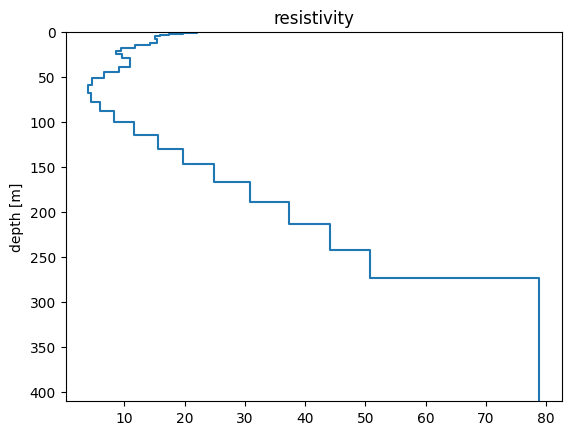

In [26]:
res_mod.plot()

In [27]:
df_res.to_csv('inversion_results.csv')

In [28]:
import plotly.express as px
import plotly.graph_objects as go

# Create scatter plot
fig = px.scatter(
    df_res,
    x='dbdt',
    y='dbdt_syn',
    color='system_id',  # Color by system type
    hover_data=['site_id', 'gate_id', 'time'],  # Additional info on hover
    title='Observed vs Synthetic dB/dt',
    labels={
        'dbdt': 'Observed dB/dt [V/m²]',
        'dbdt_syn': 'Synthetic dB/dt [V/m²]'
    }
)

# Add 1:1 line for reference
min_val = min(df_res['dbdt'].min(), df_res['dbdt_syn'].min())
max_val = max(df_res['dbdt'].max(), df_res['dbdt_syn'].max())

fig.add_trace(
    go.Scatter(
        x=[min_val, max_val],
        y=[min_val, max_val],
        mode='lines',
        name='1:1 line',
        line=dict(color='black', dash='dash')
    )
)

# Set log scale for both axes
fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    width=600,
    height=600
)

fig.show()

In [29]:
import pandas as pd
df_res2 = pd.read_csv('inversion_results.csv', index_col=0)

import plotly.express as px
import plotly.graph_objects as go

# Create scatter plot
fig = px.scatter(
    df_res2,
    x='dbdt',
    y='dbdt_syn',
    color='system_id',  # Color by system type
    hover_data=['site_id', 'gate_id', 'time'],  # Additional info on hover
    title='Observed vs Synthetic dB/dt',
    labels={
        'dbdt': 'Observed dB/dt [V/m²]',
        'dbdt_syn': 'Synthetic dB/dt [V/m²]'
    }
)

# Add 1:1 line for reference
min_val = min(df_res['dbdt'].min(), df_res['dbdt_syn'].min())
max_val = max(df_res['dbdt'].max(), df_res['dbdt_syn'].max())

fig.add_trace(
    go.Scatter(
        x=[min_val, max_val],
        y=[min_val, max_val],
        mode='lines',
        name='1:1 line',
        line=dict(color='black', dash='dash')
    )
)

# Set log scale for both axes
fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    width=600,
    height=600
)

fig.show()